In [1]:
import pandas as pd
import matplotlib.pyplot as plt
excel_data = pd.ExcelFile('data/HIDataWithTrajectory.xlsx')
# Load the data from the sheet
data = excel_data.parse('Sheet1')

# Display the first few rows of the data to understand its structure
data.head()




,Time,norHICr1,norHICr2,norHICv2,System_HI,OriginalHICr1,OriginalHICr2,OriginalHICv2,trajectoryCr1,trajectoryCr2,trajectoryCv2,trajectorySys
0,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1
1,0.017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1
2,0.033,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1
3,0.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1
4,0.067,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1


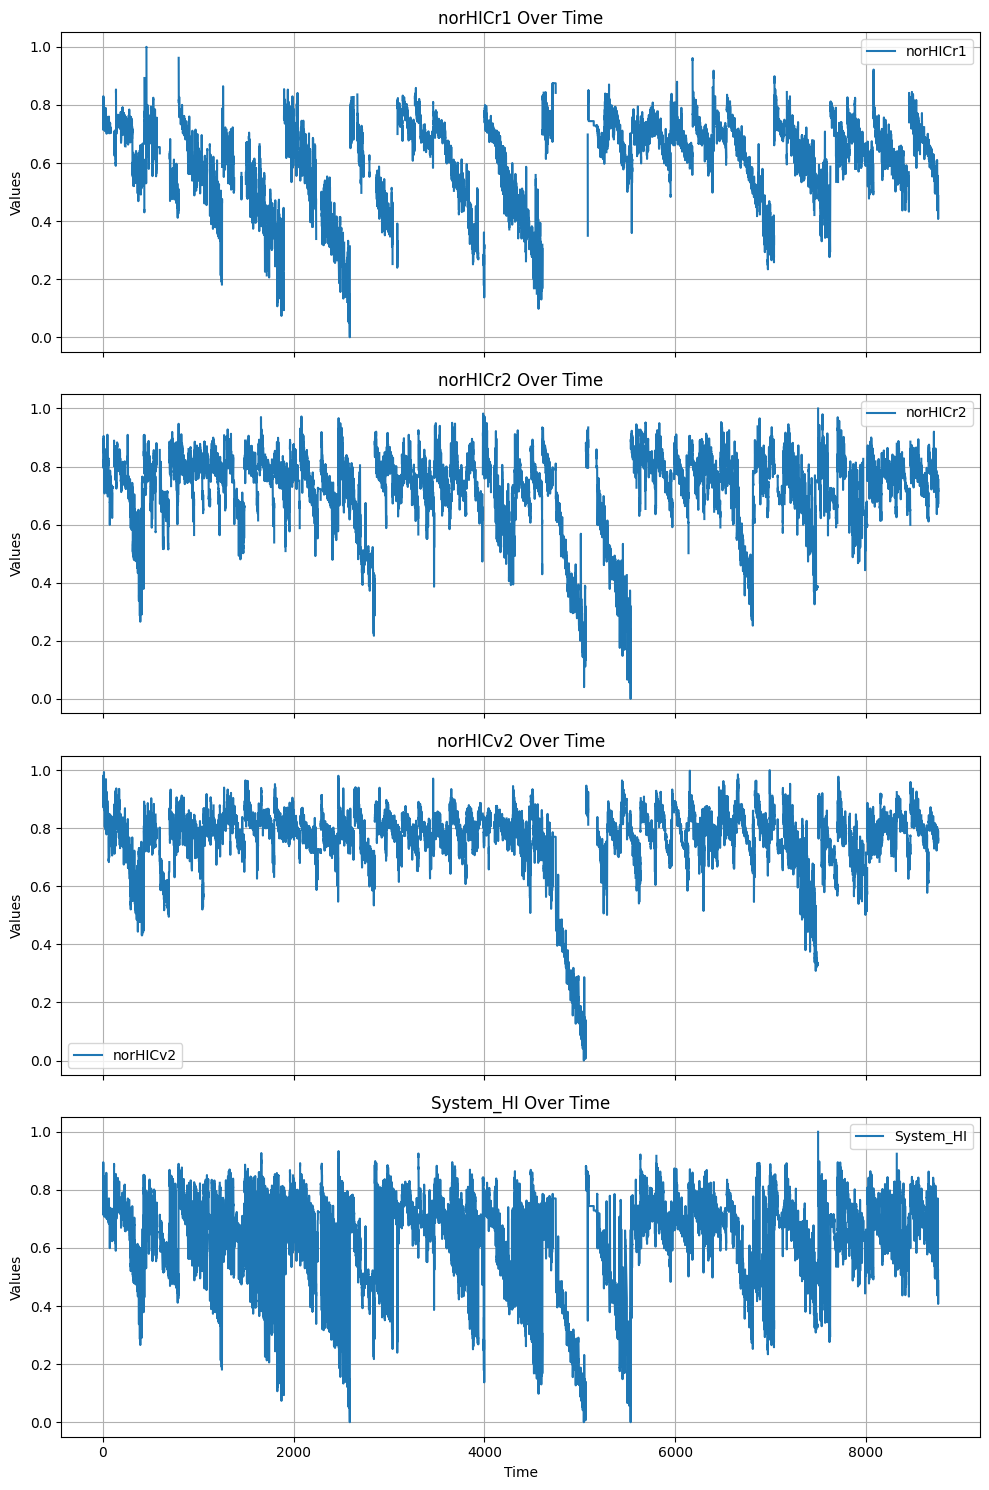

In [2]:
#visualize data before smooth

# Define the columns for visualization
columns_to_visualize = ['Time', 'norHICr1', 'norHICr2', 'norHICv2', 'System_HI']

# Ensure 'Time' is sorted for proper visualization
data.sort_values(by='Time', inplace=True)

# Create subplots: one for each column (excluding 'Time')
fig, axes = plt.subplots(len(columns_to_visualize) - 1, 1, figsize=(10, 15), sharex=True)

# Loop through each column to visualize
for i, column in enumerate(columns_to_visualize[1:]):
    axes[i].plot(data['Time'], data[column], label=column)
    axes[i].set_title(f'{column} Over Time')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)

# Set the common x-axis label
axes[-1].set_xlabel('Time')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plots
plt.show()


/tmp/ipykernel_16316/3214866423.py:25: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  .apply(rolling_with_nan)
/tmp/ipykernel_16316/3214866423.py:25: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  .apply(rolling_with_nan)
/tmp/ipykernel_16316/3214866423.py:25: FutureWarning: Not prepending group k

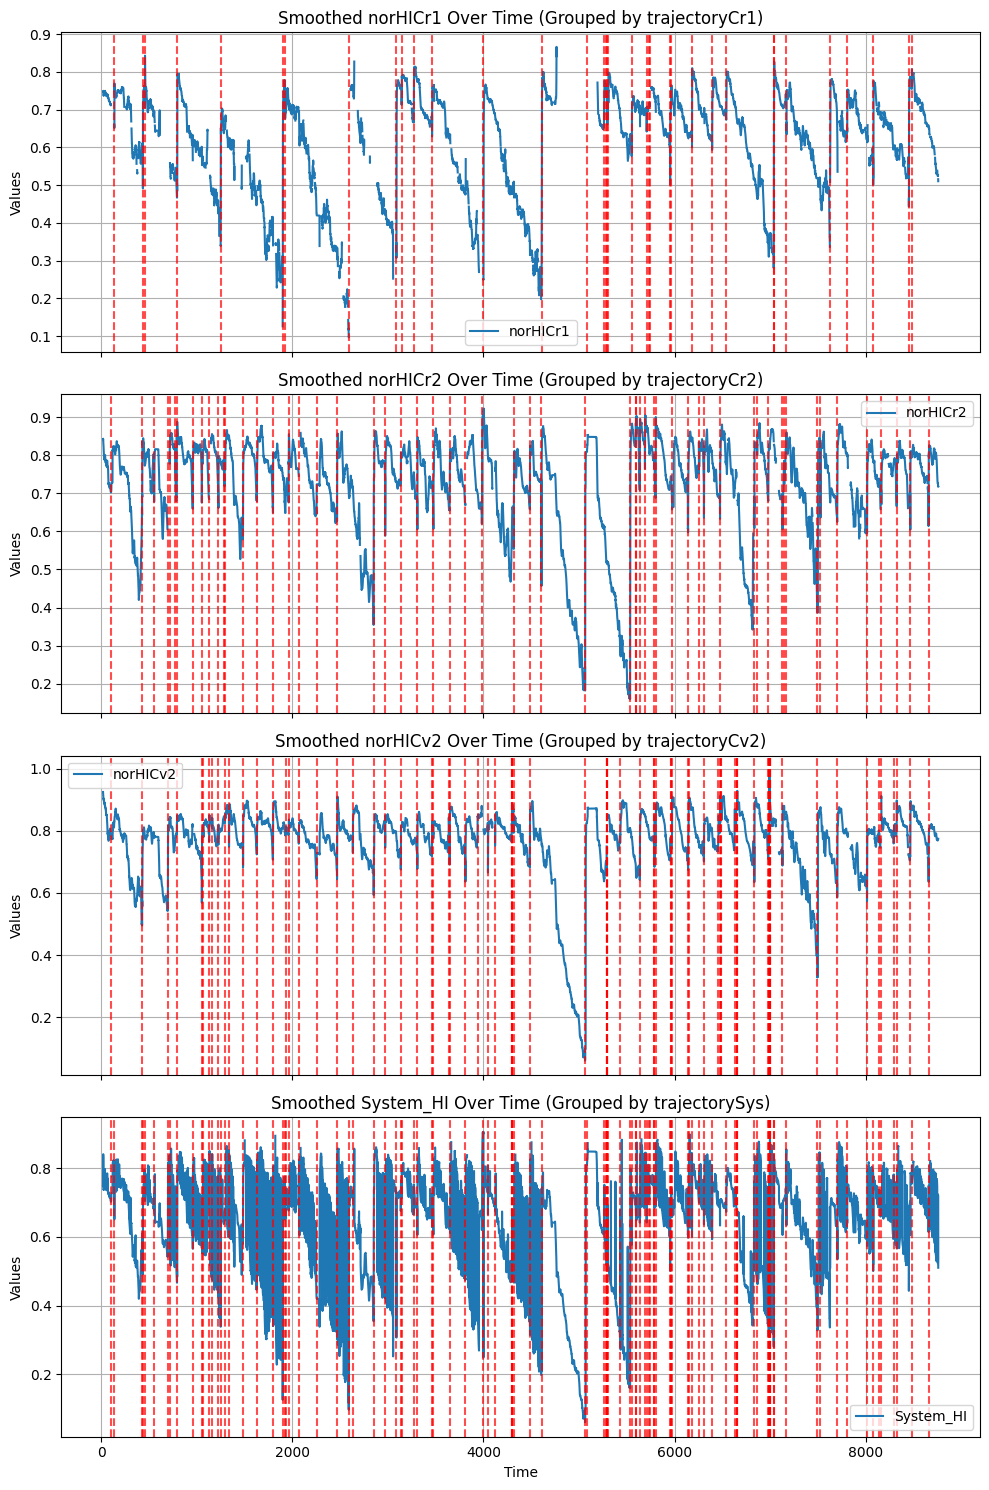

In [3]:
#Don't smooth HI system, defin HI system = min(HI_component_smooth)
import numpy as np


# Fill missing data with NaN
data = data.fillna(np.nan)

# Define the smoothing function
def rolling_with_nan(group):
    return group.rolling(window=1000, min_periods=1).apply(
        lambda x: np.nan if np.isnan(x.iloc[0]) else x.mean(), raw=False
    )

# Group by the trajectory columns and apply smoothing only within the same trajectory
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2']
columns_to_smooth = ['norHICr1', 'norHICr2', 'norHICv2']

# Initialize a DataFrame to store smoothed data
smoothed_data = data.copy()

# Apply rolling average within each group with the condition for NaN handling
for column, trajectory_column in zip(columns_to_smooth, trajectory_columns):
    smoothed_data[column] = (
        data.groupby(trajectory_column)[column]
        .apply(rolling_with_nan)
        .reset_index(level=0, drop=True)  # Align index to original DataFrame
    )

# Recalculate System_HI as the minimum of the smoothed trajectories
smoothed_data['System_HI'] = smoothed_data[columns_to_smooth].min(axis=1)

# Add the 'Time' column for visualization
smoothed_data['Time'] = data['Time']

# Identify trajectory change points
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']
transition_points = {}
for trajectory in trajectory_columns:
    transition_indices = np.where(smoothed_data[trajectory].diff().fillna(0) != 0)[0]
    transition_points[trajectory] = smoothed_data.iloc[transition_indices]['Time']

# Plot the smoothed data
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']
trajectory_labels = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']

for i, (column, trajectory) in enumerate(zip(columns_to_visualize, trajectory_columns)):
    # Plot the smoothed data
    axes[i].plot(smoothed_data['Time'], smoothed_data[column], label=column)
    axes[i].set_title(f'Smoothed {column} Over Time (Grouped by {trajectory})')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)
    
    # Add vertical red lines for trajectory changes
    for transition_time in transition_points[trajectory]:
        axes[i].axvline(x=transition_time, color='red', linestyle='--', alpha=0.7)

axes[-1].set_xlabel('Time')

plt.tight_layout()
plt.show()


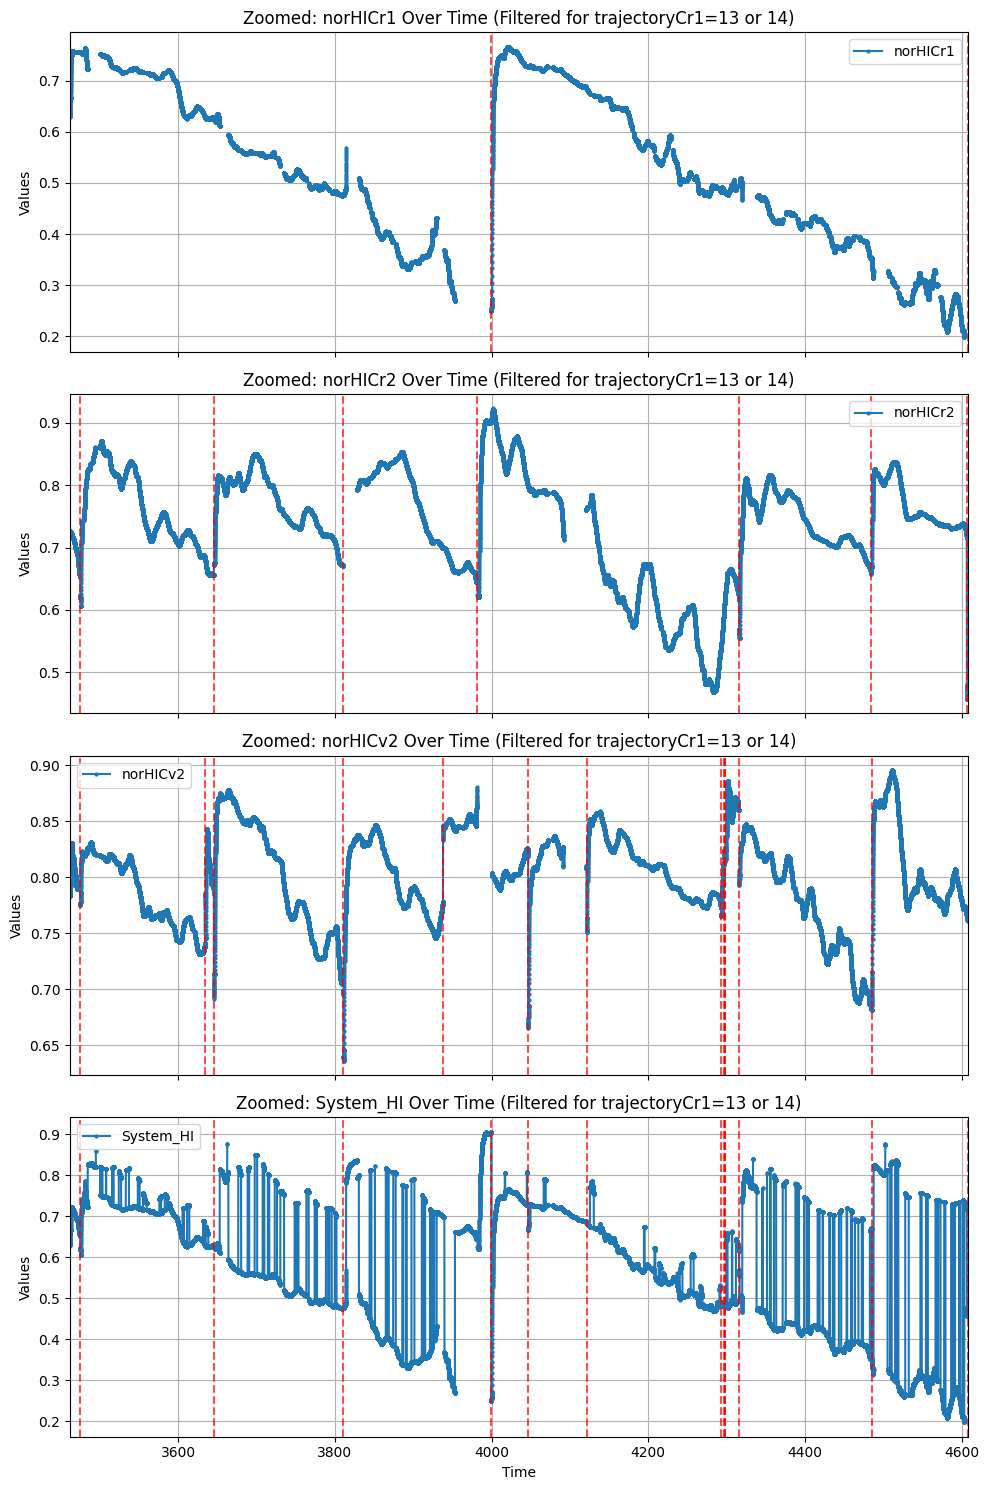

In [4]:


# Filter data for trajectoryCr1 = 8 or 9
filtered_data = smoothed_data[(smoothed_data['trajectoryCr1'] == 13) | (smoothed_data['trajectoryCr1'] == 14)]


# Plot the filtered data
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']

# Identify trajectory change points for each trajectory column
transition_points = {}
for trajectory in trajectory_columns:
    transition_indices = np.where(smoothed_data[trajectory].diff().fillna(0) != 0)[0]
    transition_points[trajectory] = smoothed_data.iloc[transition_indices]['Time']

# Plot each column with its corresponding trajectory changes
for i, (column, trajectory) in enumerate(zip(columns_to_visualize, trajectory_columns)):
    # Plot the filtered data with gaps for NaN
    axes[i].plot(filtered_data['Time'], filtered_data[column], label=column, linestyle='-', marker='o', markersize=2)
    axes[i].set_title(f'Zoomed: {column} Over Time (Filtered for trajectoryCr1=13 or 14)')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)
    axes[i].set_xlim([filtered_data['Time'].min(), filtered_data['Time'].max()])  # Adjust x-axis to the zoomed range

    # Add vertical red lines for trajectory changes corresponding to the trajectory column
    for transition_time in transition_points[trajectory]:
        axes[i].axvline(x=transition_time, color='red', linestyle='--', alpha=0.7)

# Set the x-axis label for the last subplot
axes[-1].set_xlabel('Time')

plt.tight_layout()
plt.show()


/tmp/ipykernel_16316/1555455669.py:26: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  .apply(rolling_with_nan)
/tmp/ipykernel_16316/1555455669.py:26: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  .apply(rolling_with_nan)
/tmp/ipykernel_16316/1555455669.py:26: FutureWarning: Not prepending group k

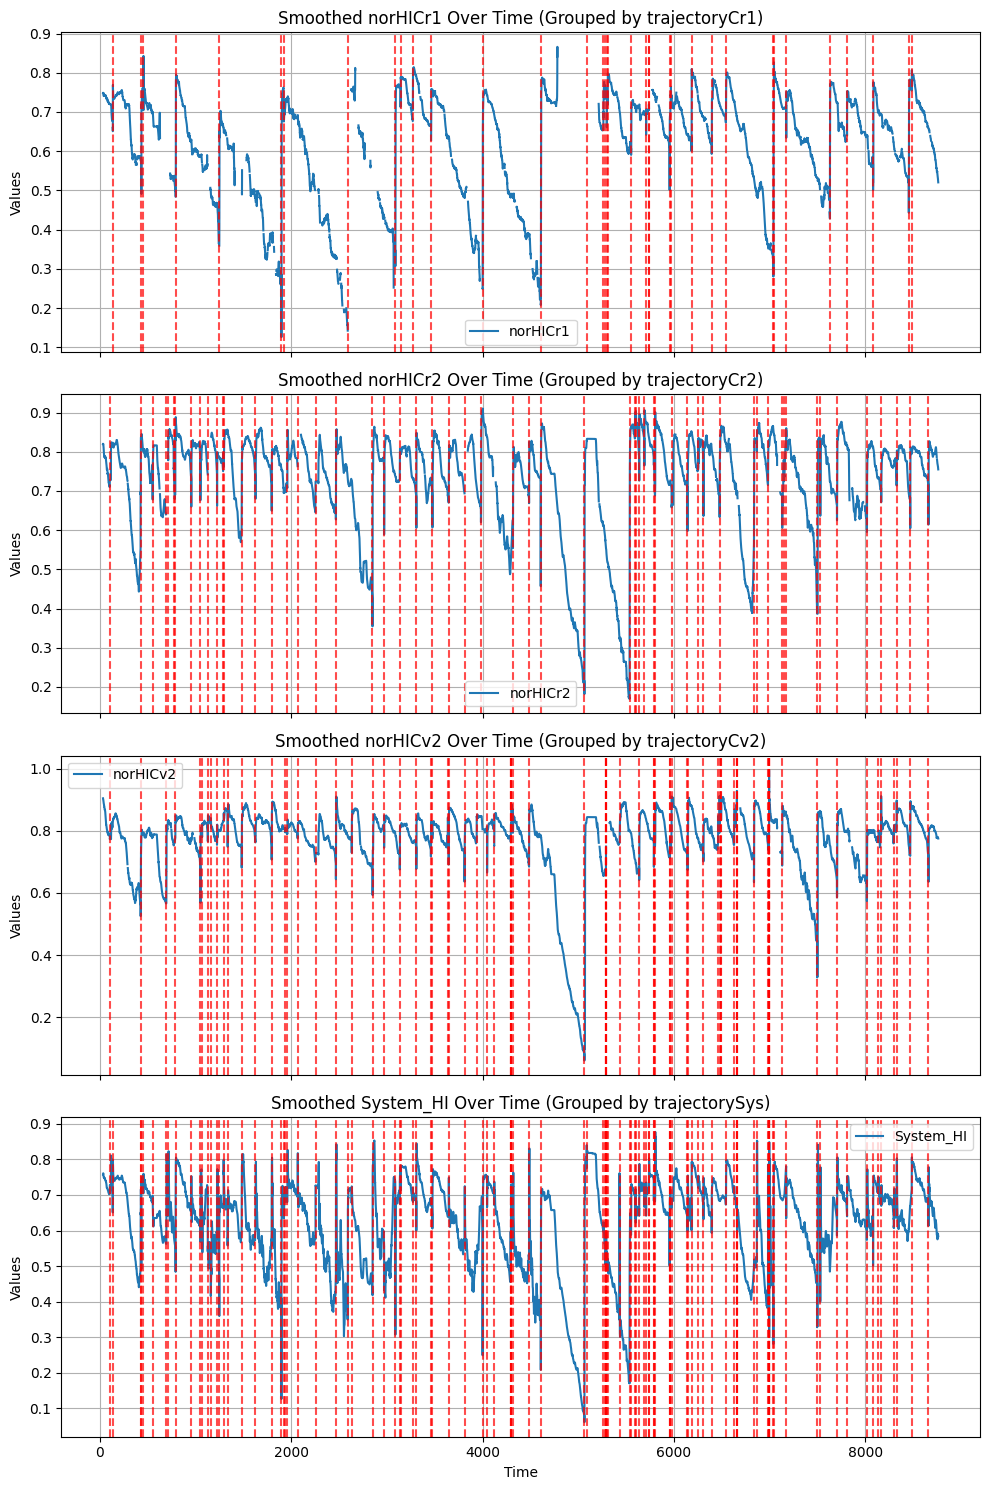

In [5]:
#smooth HI system

import numpy as np


# Fill missing data with NaN
data = data.fillna(np.nan)

# Define the smoothing function
def rolling_with_nan(group):
    return group.rolling(window=2000, min_periods=1).apply(
        lambda x: np.nan if np.isnan(x.iloc[0]) else x.mean(), raw=False
    )

# Group by the trajectory columns and apply smoothing only within the same trajectory
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2','trajectorySys']
columns_to_smooth = ['norHICr1', 'norHICr2', 'norHICv2','System_HI']

# Initialize a DataFrame to store smoothed data
smoothed_data = data.copy()

# Apply rolling average within each group with the condition for NaN handling
for column, trajectory_column in zip(columns_to_smooth, trajectory_columns):
    smoothed_data[column] = (
        data.groupby(trajectory_column)[column]
        .apply(rolling_with_nan)
        .reset_index(level=0, drop=True)  # Align index to original DataFrame
    )

# Recalculate System_HI as the minimum of the smoothed trajectories
#smoothed_data['System_HI'] = smoothed_data[columns_to_smooth].min(axis=1)

# Add the 'Time' column for visualization
smoothed_data['Time'] = data['Time']

# Identify trajectory change points
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']
transition_points = {}
for trajectory in trajectory_columns:
    transition_indices = np.where(smoothed_data[trajectory].diff().fillna(0) != 0)[0]
    transition_points[trajectory] = smoothed_data.iloc[transition_indices]['Time']

# Plot the smoothed data
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']
trajectory_labels = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']

for i, (column, trajectory) in enumerate(zip(columns_to_visualize, trajectory_columns)):
    # Plot the smoothed data
    axes[i].plot(smoothed_data['Time'], smoothed_data[column], label=column)
    axes[i].set_title(f'Smoothed {column} Over Time (Grouped by {trajectory})')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)
    
    # Add vertical red lines for trajectory changes
    for transition_time in transition_points[trajectory]:
        axes[i].axvline(x=transition_time, color='red', linestyle='--', alpha=0.7)

axes[-1].set_xlabel('Time')

plt.tight_layout()
plt.show()


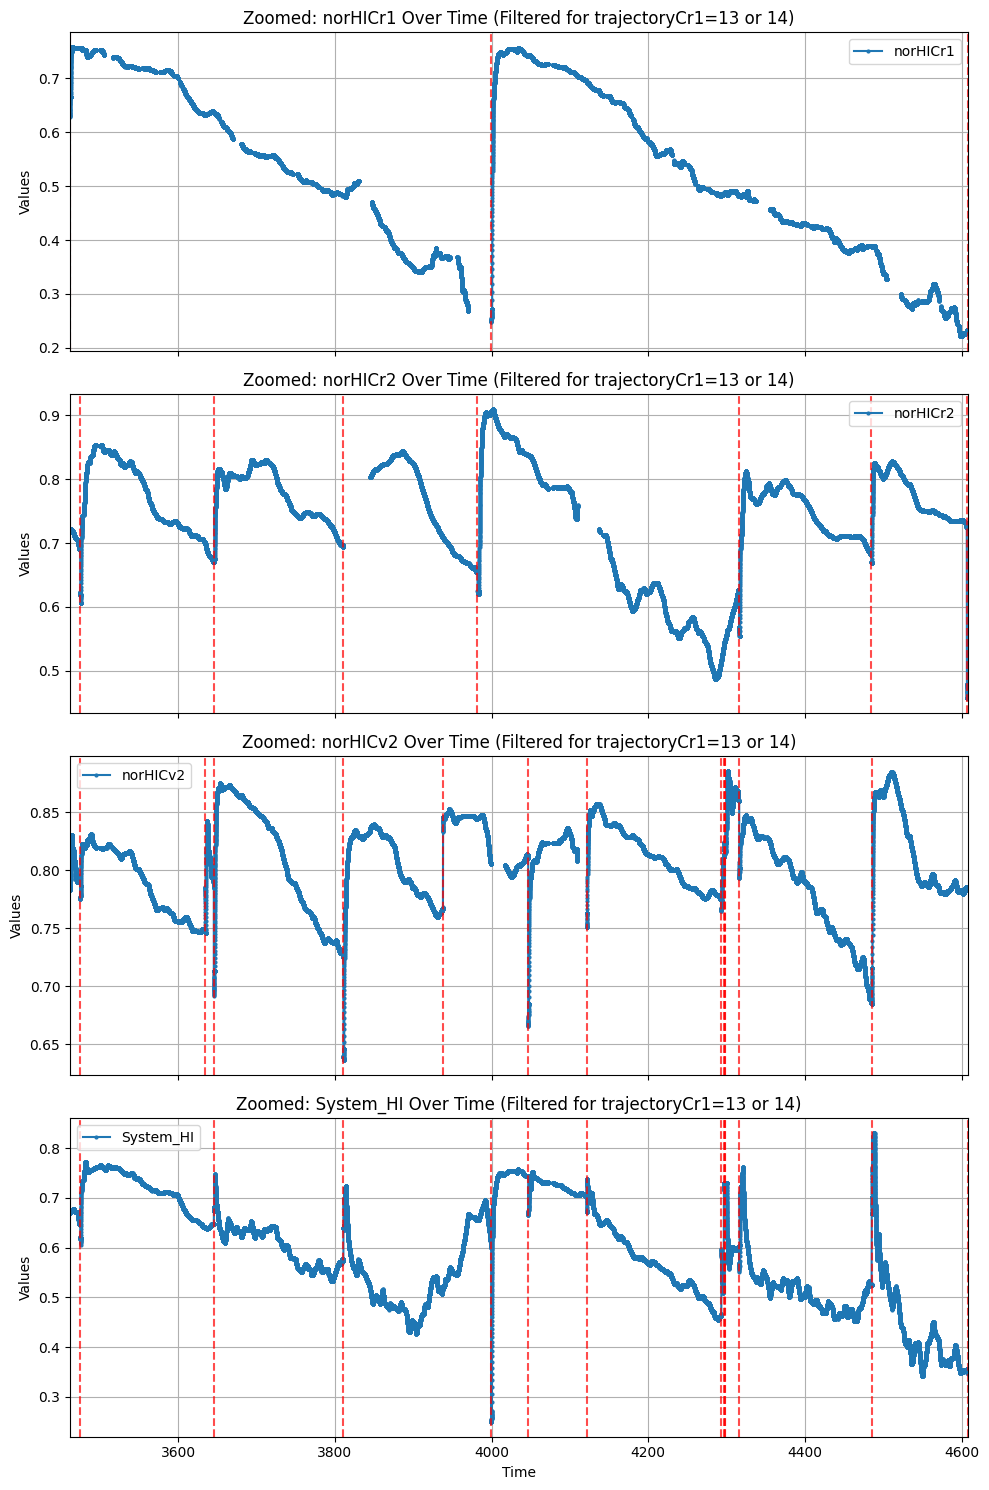

In [6]:


# Filter data for trajectoryCr1 = 8 or 9 (or 13, 14)
filtered_data = smoothed_data[(smoothed_data['trajectoryCr1'] == 13) | (smoothed_data['trajectoryCr1'] == 14)]


# Plot the filtered data
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']

# Identify trajectory change points for each trajectory column
transition_points = {}
for trajectory in trajectory_columns:
    transition_indices = np.where(smoothed_data[trajectory].diff().fillna(0) != 0)[0]
    transition_points[trajectory] = smoothed_data.iloc[transition_indices]['Time']

# Plot each column with its corresponding trajectory changes
for i, (column, trajectory) in enumerate(zip(columns_to_visualize, trajectory_columns)):
    # Plot the filtered data with gaps for NaN
    axes[i].plot(filtered_data['Time'], filtered_data[column], label=column, linestyle='-', marker='o', markersize=2)
    axes[i].set_title(f'Zoomed: {column} Over Time (Filtered for trajectoryCr1=13 or 14)')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)
    axes[i].set_xlim([filtered_data['Time'].min(), filtered_data['Time'].max()])  # Adjust x-axis to the zoomed range

    # Add vertical red lines for trajectory changes corresponding to the trajectory column
    for transition_time in transition_points[trajectory]:
        axes[i].axvline(x=transition_time, color='red', linestyle='--', alpha=0.7)

# Set the x-axis label for the last subplot
axes[-1].set_xlabel('Time')

plt.tight_layout()
plt.show()


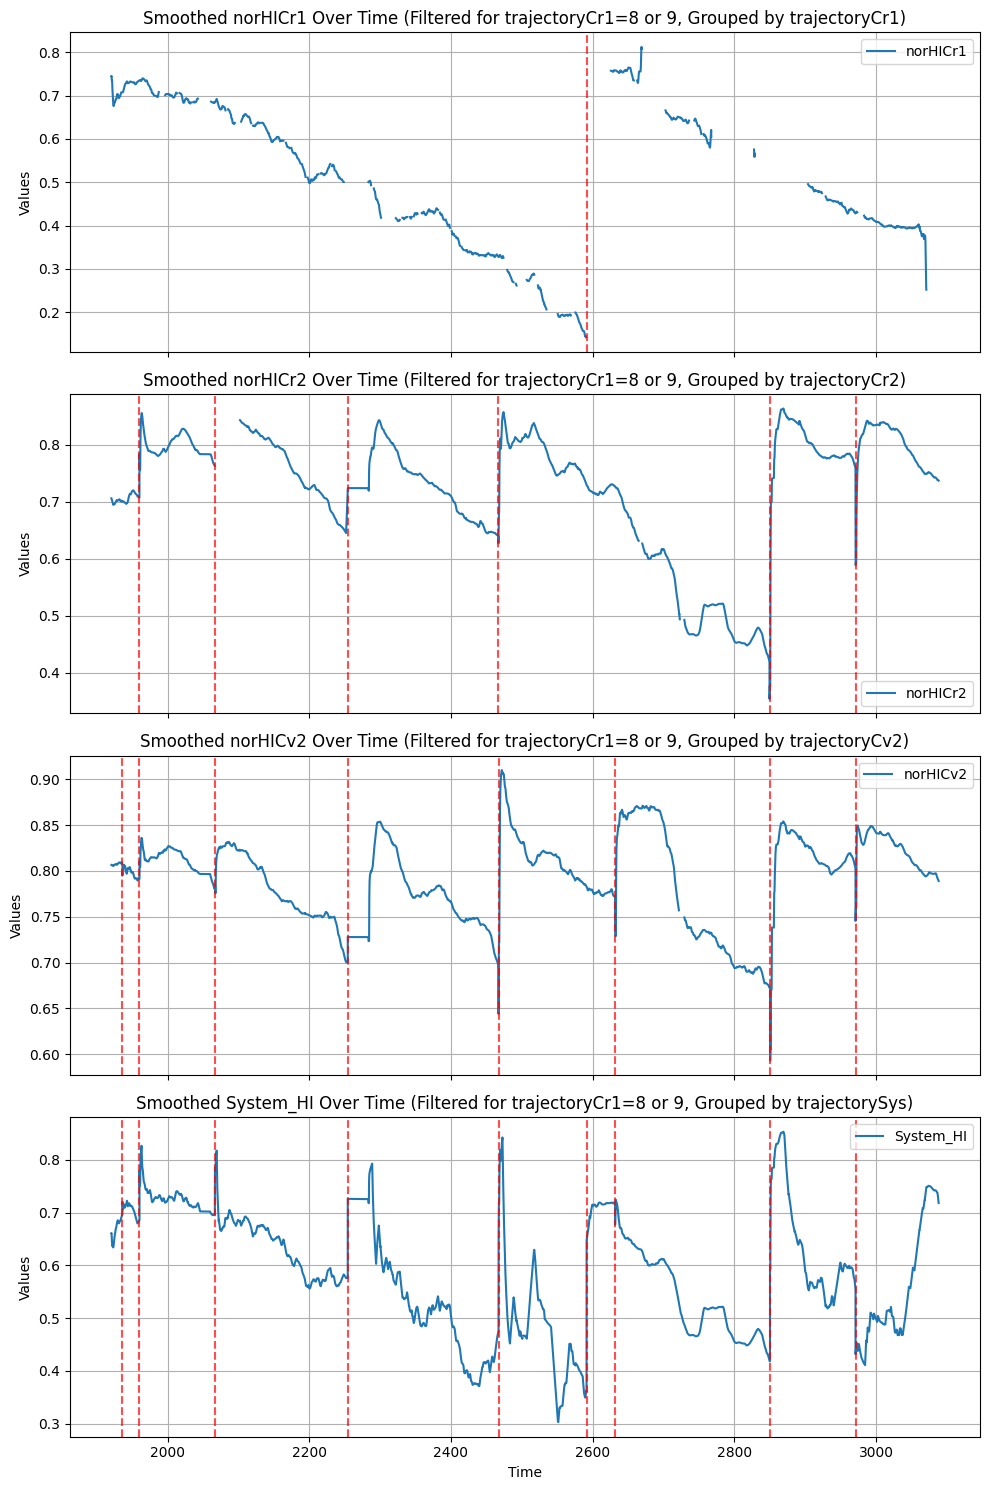

In [7]:
# Filter data for trajectoryCr1 values of 8 and 9
filtered_data = data[(data['trajectoryCr1'] == 8) | (data['trajectoryCr1'] == 9)]
filtered_smoothed_data = smoothed_data[(smoothed_data['trajectoryCr1'] == 8) | (smoothed_data['trajectoryCr1'] == 9)]

# Identify transitions in trajectory columns
transition_points = {}
trajectory_columns = ['trajectoryCr1', 'trajectoryCr2', 'trajectoryCv2', 'trajectorySys']

for trajectory in trajectory_columns:
    # Find indices where the trajectory value changes within the filtered data
    transition_indices = np.where(filtered_data[trajectory].diff().fillna(0) != 0)[0]
    transition_points[trajectory] = filtered_data.iloc[transition_indices]['Time'].values

# Plot the smoothed data with transition points for trajectoryCr1 = 8 and 9
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']

for i, (column, trajectory) in enumerate(zip(columns_to_visualize, trajectory_columns)):
    # Plot the smoothed data
    axes[i].plot(filtered_smoothed_data['Time'], filtered_smoothed_data[column], label=column)
    axes[i].set_title(f'Smoothed {column} Over Time (Filtered for trajectoryCr1=8 or 9, Grouped by {trajectory})')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)
    
    # Add vertical lines for transitions
    for transition_time in transition_points[trajectory]:
        axes[i].axvline(x=transition_time, color='red', linestyle='--', alpha=0.7)

axes[-1].set_xlabel('Time')

plt.tight_layout()
plt.show()


In [8]:
from statsmodels.nonparametric.smoothers_lowess import lowess

# Fill missing data with NaN
data = data.fillna(np.nan)
smoothed_data=filtered_data = data[(data['trajectoryCr1'] == 8) | (data['trajectoryCr1'] == 9)]


# Define LOESS smoothing function
def loess_smoothing(x, y, frac=0.1):
    """Apply LOESS smoothing to data."""
    smoothed = lowess(y, x, frac=frac, missing='drop')
    return smoothed[:, 0], smoothed[:, 1]

# Apply LOESS smoothing for each column
columns_to_visualize = ['norHICr1', 'norHICr2', 'norHICv2', 'System_HI']
smoothed_results = {}

for column in columns_to_visualize:
    smoothed_time, smoothed_values = loess_smoothing(smoothed_data['Time'], smoothed_data[column], frac=0.1)
    smoothed_results[column] = (smoothed_time, smoothed_values)

# Plot only the smoothed data and highlight missing periods
fig, axes = plt.subplots(len(columns_to_visualize), 1, figsize=(10, 15), sharex=True)

for i, column in enumerate(columns_to_visualize):
    # Smoothed trend
    smoothed_time, smoothed_values = smoothed_results[column]
    axes[i].plot(smoothed_time, smoothed_values, label=f'Smoothed {column}', color='orange')
    
    # Highlight missing data periods
    is_missing = smoothed_data[column].isna()
    if is_missing.any():
        missing_periods = smoothed_data['Time'][is_missing]
        for start, end in zip(missing_periods[:-1], missing_periods[1:]):
            axes[i].axvspan(start, end, color='gray', alpha=0.3, label='Missing Period')
    
    # Set titles and labels
    axes[i].set_title(f'{column} Over Time with LOESS Smoothing')
    axes[i].set_ylabel('Values')
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'statsmodels'